## This script aims to quantify cell type counts result from singler (label transfer method)

23 March 2026 run: update subclass to 19 (drop SUB-ProS)
19 Sep 2026 run: add Polaris and starfish assignment results

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path
import matplotlib.patches as patches
from matplotlib.widgets import PolygonSelector
import pandas as pd

# ---- Main folder = the repository folder, which holds Data/ (layout described in Data/README.md). ----
# Run this from the folder the file is in, or set the environment variable GUIDESTAR_MAIN_DIR to the repository path.
main_dir = os.environ.get('GUIDESTAR_MAIN_DIR', '..')


In [2]:
# ============================ USER SETTINGS ============================
# Methods to include, in plotting order. Any subset of
#   'gs' (trained classifier), 'bft', 'polaris', 'starfish'
# 'gs' must be listed first: it is the reference for every statistical comparison.
METHODS = ['gs', 'bft'] #, 'polaris', 'starfish']

# Method compared with GS to order the cell types on the box-plot x-axis and to
# fill `results_df` (originally BFT). Must be one of METHODS other than 'gs'.
ORDER_BY = 'bft'
# =======================================================================

ALL_METHODS = ['gs', 'bft']
_unknown = [m for m in METHODS if m not in ALL_METHODS]
assert not _unknown, f'unknown method(s) {_unknown}; choose from {ALL_METHODS}'
assert len(set(METHODS)) == len(METHODS), 'METHODS contains duplicates'
assert len(METHODS) >= 2 and METHODS[0] == 'gs', \
    "select 'gs' first plus at least one other method to compare against"
assert ORDER_BY in METHODS[1:], f'ORDER_BY must be one of {METHODS[1:]}'
print('methods:', METHODS, '| x-axis ordered by GS vs', ORDER_BY)

methods: ['gs', 'bft'] | x-axis ordered by GS vs bft


In [3]:
%matplotlib widget

In [4]:
# load csv 
d_px = 10
_BASE = os.path.join(main_dir, f'Data/20250728_Lm50GS_mbrain_3cT3')
all_gs_cells = pd.read_csv(os.path.join(_BASE, f'Final_cellpose_assign_{d_px}px_dilation/gs_seurat_analysis_19subclass/singler_cell_annotations.csv'))  # Replace with your actual file path
# BFT is only loaded when selected in the settings cell
all_bft_cells = (pd.read_csv(os.path.join(_BASE, f'Final_cellpose_assign_{d_px}px_dilation/bft_seurat_analysis_19subclass/singler_cell_annotations.csv'))
                 if 'bft' in METHODS else None)

all_cells = all_gs_cells.rename(columns={
    col: {"x_global_px": "spatial_1",
          "y_global_px": "spatial_2"}[col]
    for col in all_gs_cells.columns
    if col in ["x_global_px", "y_global_px"]
})

if all_bft_cells is not None:
    all_bft_cells = all_bft_cells.rename(columns={
        col: {"x_global_px": "spatial_1",
              "y_global_px": "spatial_2"}[col]
        for col in all_bft_cells.columns
        if col in ["x_global_px", "y_global_px"]
    })

all_cells = all_cells[all_cells['delta_next']>=0.012]
all_bft_cells = all_bft_cells[all_bft_cells['delta_next']>=0.012]

In [ ]:
# load csv 
d_px = 10
_OUT = os.path.join(_BASE, f'Final_cellpose_assign_{d_px}px_dilation')
os.makedirs(_OUT, exist_ok=True)

METHOD_ORDER  = list(METHODS)                                 # plotting order, from the settings cell
METHOD_TITLE  = {'gs': 'GS', 'bft': 'BFT'}
METHOD_LEGEND = {'gs': 'Trained Classifier', 'bft': 'BFT'}
FIG_SUFFIX    = '_'.join(METHOD_TITLE[m] for m in METHOD_ORDER)   # e.g. 'GS_BFT'

def load_annotations(method):
    df = pd.read_csv(os.path.join(_OUT, f'{method}_seurat_analysis_19subclass/singler_cell_annotations.csv'))
    return df.rename(columns={"x_global_px": "spatial_1", "y_global_px": "spatial_2"})

cells_by_method = {m: load_annotations(m) for m in METHOD_ORDER}

# kept so existing cells that reference these names still work
all_cells = cells_by_method['gs']
all_bft_cells = cells_by_method.get('bft')    # None when BFT is not selected

In [7]:
pd.DataFrame({m: df['delta_next'].describe() for m, df in cells_by_method.items()})

,gs,bft
count,3667.000000,3643.000000
mean,0.097472,0.093150
std,0.076687,0.077017
min,0.000000,0.000000
25%,0.050099,0.039069
50%,0.077890,0.072754
75%,0.136896,0.127398
max,0.700105,0.581520


In [8]:
pd.Series({m: df['score'].max() for m, df in cells_by_method.items()}, name='max score')

gs     0.606097
bft    0.600327
Name: max score, dtype: float64

In [9]:
from tifffile import imread

dapi_img = imread(os.path.join(main_dir, "Data/20250728_Lm50GS_mbrain_3cT3/Fused_DAPI.tif"))
downsample_factor = 4
dapi_small = dapi_img[::downsample_factor, ::downsample_factor]

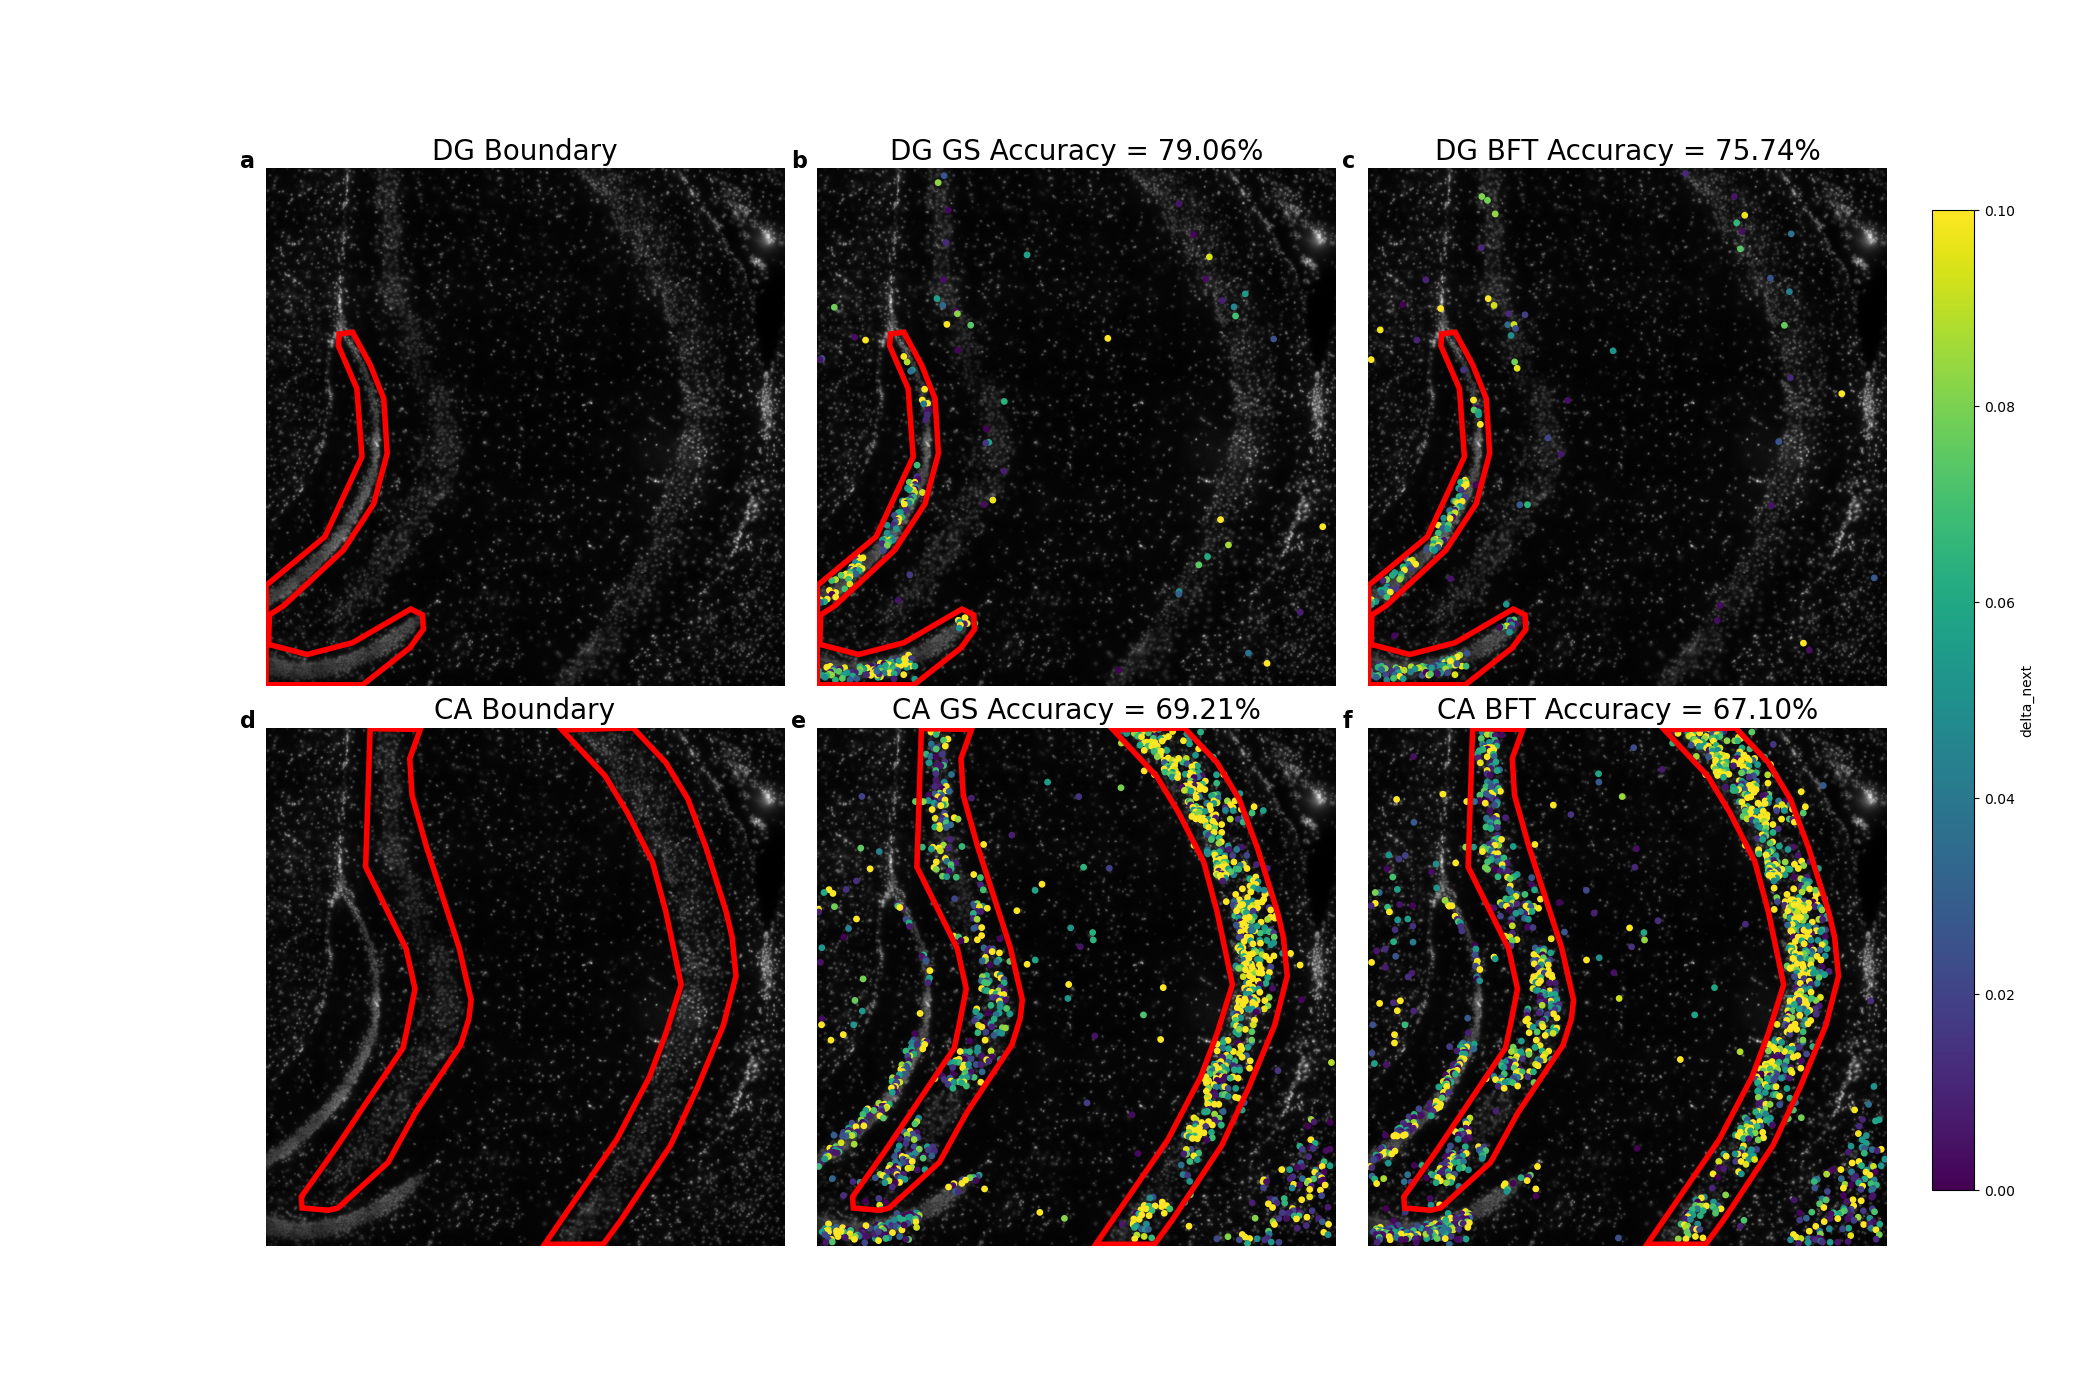

,region,method,n_cells,n_inside,accuracy
0,DG,gs,234,185,0.790598
1,DG,bft,202,153,0.757426
2,CA,gs,1260,872,0.692063
3,CA,bft,1556,1044,0.670951


In [10]:
import string
dg_vertices = np.load(os.path.join('../DataForFigures/region_boundary/dg_boundary_polygon_vertices.npy'))
selected_vertices = np.load(os.path.join('../DataForFigures/region_boundary/ca3_boundary_polygon_vertices_refined.npy'))
target_vertices_2 = np.load(os.path.join('../DataForFigures/region_boundary/ca1_boundary_polygon_vertices.npy'))

global_vmin = 0 
global_vmax = 0.1 # 0.5 # for SingleR score
plot_scores = 'delta_next'  # or 'score'

REGIONS = [  # (name, SingleR labels, polygons a cell may fall in)
    ('DG', ['DG'],                           [dg_vertices]),
    ('CA', ['CA1-ProS', 'CA2-IG-FC', 'CA3'], [selected_vertices, target_vertices_2]),  # CA3, CA1
]

def inside_regions(df, polygons):
    """True where a cell centroid lies inside any of the polygons."""
    xy = df[['spatial_1', 'spatial_2']].to_numpy()
    inside = np.zeros(len(xy), dtype=bool)
    for poly in polygons:
        inside |= Path(poly).contains_points(xy)
    return inside

plt.close('all')
n_col = len(METHOD_ORDER) + 1                     # boundary + one panel per method
panel_labels = string.ascii_lowercase[:2 * n_col]
fig, ax = plt.subplots(2, n_col, figsize=(7 * n_col, 14))

accuracy_rows = []
for r, (region, types, polys) in enumerate(REGIONS):
    for a in ax[r]:
        a.imshow(dapi_small, cmap='gray', origin='upper', extent=[0, 20480, 20482, 0])

    for c, m in enumerate(METHOD_ORDER, start=1):
        target = cells_by_method[m][cells_by_method[m]['label_raw'].isin(types)]
        inside = inside_regions(target, polys)
        sc = ax[r, c].scatter(
            target['spatial_1'], target['spatial_2'],
            c=target[plot_scores], cmap='viridis', s=15,
            vmin=global_vmin, vmax=global_vmax
        )
        ax[r, c].set_title(f'{region} {METHOD_TITLE[m]} Accuracy = {inside.mean():.2%}', fontsize=20)
        accuracy_rows.append({'region': region, 'method': m, 'n_cells': len(target),
                               'n_inside': int(inside.sum()), 'accuracy': inside.mean()})

    for a in ax[r]:                                # polygon on top, incl. boundary panel
        for poly in polys:
            a.add_patch(patches.Polygon(poly, fill=False, edgecolor='red', linewidth=4))
    ax[r, 0].set_title(f'{region} Boundary', fontsize=20)

cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
cbar = fig.colorbar(sc, cax=cbar_ax)
cbar.set_label(plot_scores)

for i, a in enumerate(ax.flatten()):
    a.axis('off')
    a.set_aspect('equal')
    a.text(-0.05, 1.0, panel_labels[i], fontsize=16, weight='bold', transform=a.transAxes)

plt.subplots_adjust(wspace=0.05, hspace=0.08, right=0.9)
plt.savefig(os.path.join(_OUT, f'DG_CA_final_{plot_scores}_plot_{FIG_SUFFIX}.svg'))
plt.show()

accuracy_df = pd.DataFrame(accuracy_rows)
accuracy_df.to_csv(os.path.join(_OUT, f'DG_CA_accuracy_{FIG_SUFFIX}.csv'), index=False)
accuracy_df

### DG Crop

<user_home>\AppData\Local\Temp\ipykernel_107280\2407177001.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


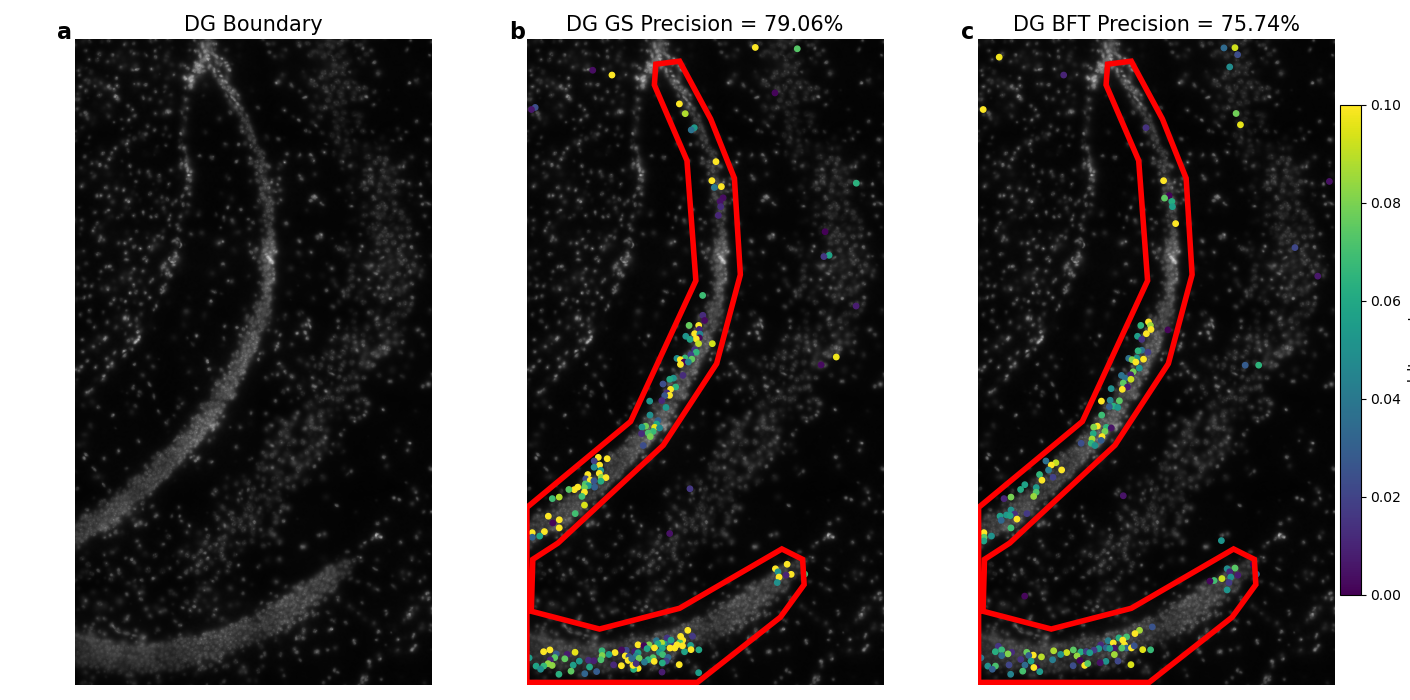

In [11]:
plt.close('all')

plot_scores = 'delta_next'
region, types, polys = REGIONS[0]                 # DG
n_col = len(METHOD_ORDER) + 1
fig, ax = plt.subplots(1, n_col, figsize=(4.7 * n_col, 7), sharex=True, sharey=True)

for a in ax:
    a.imshow(dapi_small, cmap='gray', origin='upper', extent=[0, 20480, 20480, 0])

for c, m in enumerate(METHOD_ORDER, start=1):
    target = cells_by_method[m][cells_by_method[m]['label_raw'].isin(types)]
    inside = inside_regions(target, polys)
    sc = ax[c].scatter(
        target['spatial_1'], target['spatial_2'],
        c=target[plot_scores], cmap='viridis', s=15,
        vmin=global_vmin, vmax=global_vmax
    )
    for poly in polys:
        ax[c].add_patch(patches.Polygon(poly, fill=False, edgecolor='red', linewidth=4))
    ax[c].set_title(f'{region} {METHOD_TITLE[m]} Precision = {inside.mean():.2%}', fontsize=15)
ax[0].set_title(f'{region} Boundary', fontsize=15)

cbar_ax = fig.add_axes([0.95, 0.15, 0.015, 0.7])
cbar = fig.colorbar(sc, cax=cbar_ax)
cbar.set_label(plot_scores)

for i, a in enumerate(ax):
    a.axis('off')
    a.set_aspect('equal')
    a.text(-0.05, 1.0, panel_labels[i], fontsize=16, weight='bold', transform=a.transAxes)

plt.setp(ax, xlim=(0, 8000), ylim=(6000, 20480))
plt.subplots_adjust(wspace=0.05, hspace=0.08, right=0.9)
for a in ax:
    a.invert_yaxis()
plt.tight_layout()
plt.savefig(os.path.join(_OUT, f'DG_zoomed_final_plot_{FIG_SUFFIX}.svg'))
plt.show()

# SingleR side by side boxplot

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind

In [14]:
# process the data (fresh read, unfiltered — same as before)
HUE_ORDER = [f'{m}_{d_px}px' for m in METHOD_ORDER]      # gs first = reference
REF = HUE_ORDER[0]
combined_df = pd.concat(
    [load_annotations(m).assign(data_type=f'{m}_{d_px}px') for m in METHOD_ORDER],
    ignore_index=True
)
combined_df['data_type'].value_counts()

gs_10px     3667
bft_10px    3643
Name: data_type, dtype: int64

In [15]:
# drop cell types with sample size < 30
# Rule uses the ORDER_BY method's counts (BFT by default, as in the original).
# Add other '<method>_{d_px}px' entries to apply it to more methods
# (this can drop extra cell types from the figure).
ORDER_BY_DT = f'{ORDER_BY}_{d_px}px'
LOW_COUNT_FROM = [ORDER_BY_DT]
low_count_cell_types = sorted({
    ct
    for dt in LOW_COUNT_FROM
    for ct in combined_df.loc[combined_df['data_type'] == dt, 'label_raw']
                         .value_counts().loc[lambda s: s < 30].index
})
print(f'Cell types with sample size < 30 in {LOW_COUNT_FROM}: {low_count_cell_types}')
combined_df_sub = combined_df[~combined_df['label_raw'].isin(low_count_cell_types)]

rows = []
for ct in combined_df_sub["label_raw"].unique():
    subset = combined_df_sub[combined_df_sub["label_raw"] == ct]
    ref = subset[subset["data_type"] == REF]
    for other in HUE_ORDER[1:]:
        oth = subset[subset["data_type"] == other]
        if ref.empty or oth.empty:
            continue  # need both groups
        stat, p = ttest_ind(ref["score"], oth["score"], equal_var=False)
        stat_d, p_d = ttest_ind(ref["delta_next"], oth["delta_next"], equal_var=False)
        rows.append({
            "cell_type": ct,
            "gs": REF,
            "other": other,
            "t_stat": stat,
            "p_value": p,
            "t_stat_deltanext": stat_d,
            "p_value_deltanext": p_d,
            "n_gs": len(ref),
            "n_other": len(oth),
            "median_gs_scores": ref["score"].median(),
            "median_other_scores": oth["score"].median(),
            "median_gs_deltanext": ref["delta_next"].median(),
            "median_other_deltanext": oth["delta_next"].median(),
        })

results_long = pd.DataFrame(rows)   # GS vs every other selected method

# GS vs the ORDER_BY method in the original column layout, so the later cells and the
# sort order are unchanged. NOTE: the 'bft' column names are kept for compatibility;
# they hold the ORDER_BY method's values (BFT by default).
results_df = (
    results_long[results_long["other"] == ORDER_BY_DT]
    .rename(columns={"other": "bft", "n_other": "n_bft",
                     "median_other_scores": "median_bft_scores",
                     "median_other_deltanext": "median_bft_deltanext"})
    .reset_index(drop=True)
)
print(f'results_df = GS vs {ORDER_BY_DT}')
results_long

Cell types with sample size < 30 in ['bft_10px']: ['CR', 'L6 IT CTX', 'Lamp5', 'Sncg', 'Sst Chodl']
results_df = GS vs bft_10px


,cell_type,gs,other,t_stat,p_value,t_stat_deltanext,p_value_deltanext,n_gs,n_other,median_gs_scores,median_other_scores,median_gs_deltanext,median_other_deltanext
0,VLMC,gs_10px,bft_10px,-2.288461,2.351989e-02,-1.235247,0.218764,78,73,0.242780,0.262566,0.069741,0.084925
1,Oligo,gs_10px,bft_10px,-4.548875,7.244516e-06,1.505041,0.133101,206,199,0.265092,0.301000,0.082510,0.076581
2,Astro,gs_10px,bft_10px,-9.741479,7.345910e-22,-2.751439,0.005995,1047,847,0.314293,0.349795,0.120136,0.128778
3,Endo,gs_10px,bft_10px,-3.048507,2.559271e-03,-1.023444,0.307064,158,118,0.296248,0.323000,0.107455,0.110940
4,CA1-ProS,gs_10px,bft_10px,-8.037307,1.740199e-15,3.578387,0.000356,782,861,0.381539,0.414628,0.076706,0.069420
5,L6b CTX,gs_10px,bft_10px,-2.239028,2.624591e-02,1.550103,0.122653,97,117,0.308515,0.322753,0.077235,0.064541
6,L6 CT CTX,gs_10px,bft_10px,-1.510590,1.335842e-01,0.334480,0.738687,57,73,0.290497,0.313486,0.069151,0.083355
7,SMC-Peri,gs_10px,bft_10px,-0.851688,3.965054e-01,-0.548543,0.584581,67,49,0.243508,0.248598,0.063139,0.066853
8,Pvalb,gs_10px,bft_10px,-4.873596,1.782706e-06,0.260995,0.794272,213,158,0.315041,0.351883,0.055962,0.051058
9,CA2-IG-FC,gs_10px,bft_10px,-3.483609,5.297483e-04,0.263862,0.791982,275,352,0.366863,0.401371,0.050153,0.050808


In [16]:
results_df['gs-bf-median_ratio'] = results_df['median_gs_scores']/ results_df['median_bft_scores']
results_df['gs-bf-median_deltanext'] = results_df['median_gs_deltanext']/ results_df['median_bft_deltanext']

In [17]:
results_df.sort_values(by="gs-bf-median_deltanext", ascending=False)

,cell_type,gs,bft,t_stat,p_value,t_stat_deltanext,p_value_deltanext,n_gs,n_bft,median_gs_scores,median_bft_scores,median_gs_deltanext,median_bft_deltanext,gs-bf-median_ratio,gs-bf-median_deltanext
5,L6b CTX,gs_10px,bft_10px,-2.239028,2.624591e-02,1.550103,0.122653,97,117,0.308515,0.322753,0.077235,0.064541,0.955884,1.196675
4,CA1-ProS,gs_10px,bft_10px,-8.037307,1.740199e-15,3.578387,0.000356,782,861,0.381539,0.414628,0.076706,0.069420,0.920196,1.104959
8,Pvalb,gs_10px,bft_10px,-4.873596,1.782706e-06,0.260995,0.794272,213,158,0.315041,0.351883,0.055962,0.051058,0.895299,1.096066
11,DG,gs_10px,bft_10px,-2.757099,6.108794e-03,1.770132,0.077408,234,202,0.358711,0.390942,0.059280,0.054611,0.917555,1.085498
1,Oligo,gs_10px,bft_10px,-4.548875,7.244516e-06,1.505041,0.133101,206,199,0.265092,0.301000,0.082510,0.076581,0.880706,1.077424
10,Micro-PVM,gs_10px,bft_10px,-0.600478,5.499872e-01,-0.921299,0.359951,68,40,0.189068,0.176619,0.064160,0.064089,1.070486,1.001104
9,CA2-IG-FC,gs_10px,bft_10px,-3.483609,5.297483e-04,0.263862,0.791982,275,352,0.366863,0.401371,0.050153,0.050808,0.914023,0.987106
3,Endo,gs_10px,bft_10px,-3.048507,2.559271e-03,-1.023444,0.307064,158,118,0.296248,0.323000,0.107455,0.110940,0.917175,0.968585
7,SMC-Peri,gs_10px,bft_10px,-0.851688,3.965054e-01,-0.548543,0.584581,67,49,0.243508,0.248598,0.063139,0.066853,0.979526,0.944438
2,Astro,gs_10px,bft_10px,-9.741479,7.345910e-22,-2.751439,0.005995,1047,847,0.314293,0.349795,0.120136,0.128778,0.898507,0.932894


In [18]:
np.round(results_df.sort_values(by="gs-bf-median_deltanext", ascending=False)['p_value_deltanext'].values, 3)

array([0.123, 0.   , 0.794, 0.077, 0.133, 0.36 , 0.792, 0.307, 0.585,
       0.006, 0.017, 0.271, 0.739, 0.219])

In [29]:
results_df[results_df['p_value'] < 0.05].sort_values(by="gs-bf-median_deltanext", ascending=False)

,cell_type,gs,bft,t_stat,p_value,t_stat_deltanext,p_value_deltanext,n_gs,n_bft,median_gs_scores,median_bft_scores,median_gs_deltanext,median_bft_deltanext,gs-bf-median_ratio,gs-bf-median_deltanext
5,L6b CTX,gs_10px,bft_10px,-2.239028,2.624591e-02,1.550103,0.122653,97,117,0.308515,0.322753,0.077235,0.064541,0.955884,1.196675
4,CA1-ProS,gs_10px,bft_10px,-8.037307,1.740199e-15,3.578387,0.000356,782,861,0.381539,0.414628,0.076706,0.069420,0.920196,1.104959
8,Pvalb,gs_10px,bft_10px,-4.873596,1.782706e-06,0.260995,0.794272,213,158,0.315041,0.351883,0.055962,0.051058,0.895299,1.096066
11,DG,gs_10px,bft_10px,-2.757099,6.108794e-03,1.770132,0.077408,234,202,0.358711,0.390942,0.059280,0.054611,0.917555,1.085498
1,Oligo,gs_10px,bft_10px,-4.548875,7.244516e-06,1.505041,0.133101,206,199,0.265092,0.301000,0.082510,0.076581,0.880706,1.077424
9,CA2-IG-FC,gs_10px,bft_10px,-3.483609,5.297483e-04,0.263862,0.791982,275,352,0.366863,0.401371,0.050153,0.050808,0.914023,0.987106
3,Endo,gs_10px,bft_10px,-3.048507,2.559271e-03,-1.023444,0.307064,158,118,0.296248,0.323000,0.107455,0.110940,0.917175,0.968585
2,Astro,gs_10px,bft_10px,-9.741479,7.345910e-22,-2.751439,0.005995,1047,847,0.314293,0.349795,0.120136,0.128778,0.898507,0.932894
13,CA3,gs_10px,bft_10px,-4.485319,9.252943e-06,-2.397531,0.016881,203,343,0.354118,0.392554,0.050161,0.055275,0.902087,0.907480
0,VLMC,gs_10px,bft_10px,-2.288461,2.351989e-02,-1.235247,0.218764,78,73,0.242780,0.262566,0.069741,0.084925,0.924646,0.821200


In [20]:
results_df[results_df['p_value_deltanext'] < 0.05].sort_values(by="gs-bf-median_deltanext", ascending=False)

,cell_type,gs,bft,t_stat,p_value,t_stat_deltanext,p_value_deltanext,n_gs,n_bft,median_gs_scores,median_bft_scores,median_gs_deltanext,median_bft_deltanext,gs-bf-median_ratio,gs-bf-median_deltanext
4,CA1-ProS,gs_10px,bft_10px,-8.037307,1.740199e-15,3.578387,0.000356,782,861,0.381539,0.414628,0.076706,0.069420,0.920196,1.104959
2,Astro,gs_10px,bft_10px,-9.741479,7.345910e-22,-2.751439,0.005995,1047,847,0.314293,0.349795,0.120136,0.128778,0.898507,0.932894
13,CA3,gs_10px,bft_10px,-4.485319,9.252943e-06,-2.397531,0.016881,203,343,0.354118,0.392554,0.050161,0.055275,0.902087,0.907480


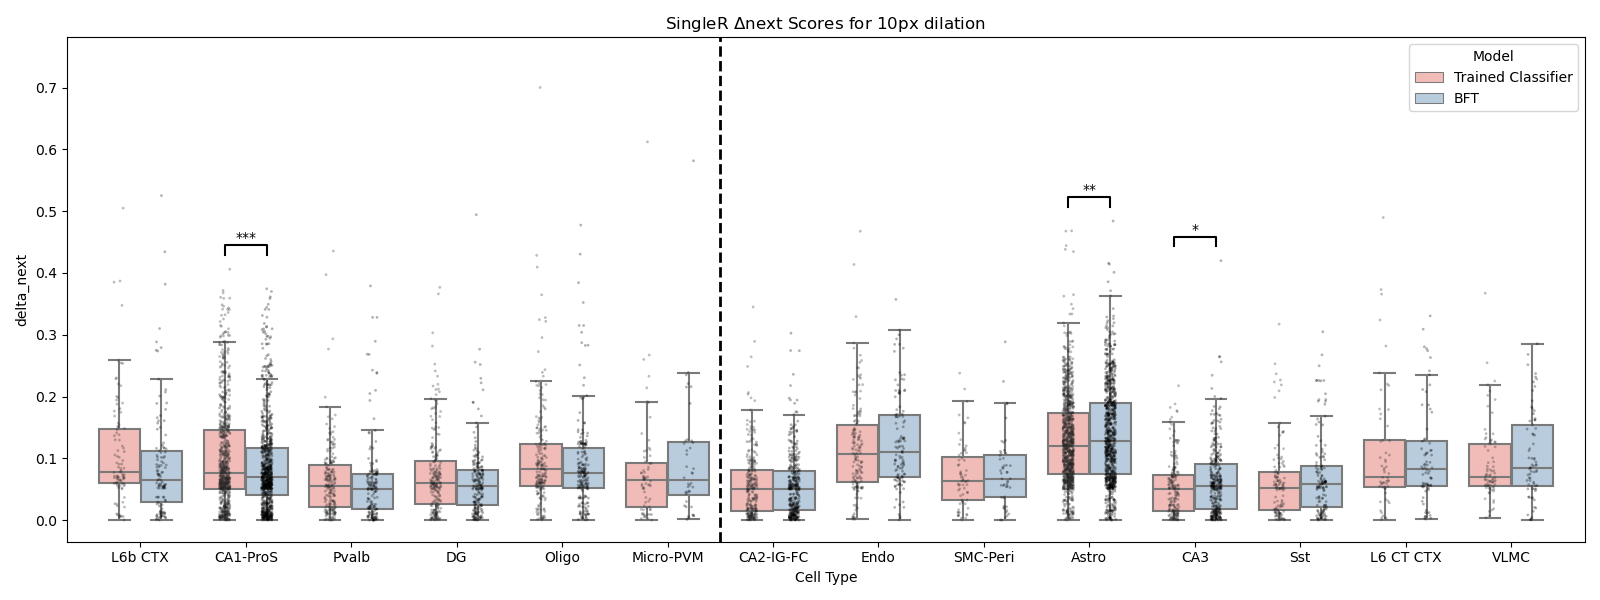

In [ ]:
# ---------------------------------------------------------------------------
# Significance annotation helpers
# ---------------------------------------------------------------------------
def p_to_stars(p, ns_label=''):
    """Standard star notation. Set ns_label='ns' to mark non-significant groups."""
    if p is None or np.isnan(p):
        return ''
    if p < 0.001:
        return '***'
    if p < 0.01:
        return '**'
    if p < 0.05:
        return '*'
    return ns_label


def add_significance(ax, x1, x2, y, h, text):
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=1.5, c='black')
    ax.text((x1 + x2) / 2, y + h, text, ha='center', va='bottom')


# ---------------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------------
# Deduplicate while preserving sort order, in case results_df has repeats.
sort_order = list(dict.fromkeys(
    results_df.sort_values(by="gs-bf-median_deltanext", ascending=False)['cell_type']
))

plt.close('all')
plt.figure(figsize=(16, 6))
plt.title(f"SingleR $\\Delta$next Scores for {d_px}px dilation")

ax = sns.boxplot(
    x="label_raw",
    y="delta_next",
    hue="data_type",
    data=combined_df_sub,
    palette="Pastel1",
    order=sort_order,
    showfliers=False
)

# Capture handles HERE -- before stripplot appends its own duplicate set.
box_handles, box_labels = ax.get_legend_handles_labels()

sns.stripplot(
    x="label_raw",
    y="delta_next",
    hue="data_type",
    data=combined_df_sub,
    order=sort_order,
    dodge=True,
    color="black",
    alpha=0.3,
    size=2,
)
# No legend= kwarg here: it does not exist before seaborn 0.13, and it is not
# needed. The stripplot does register its own hue handles, but the explicit
# ax.legend(box_handles, ...) at the bottom replaces the legend entirely.

ax.axvline(x=5.5, color="black", linestyle="--", linewidth=2)

# ---------------------------------------------------------------------------
# Significance brackets, one per cell type, driven by results_df
# ---------------------------------------------------------------------------
xpos = {ct: i for i, ct in enumerate(sort_order)}

# Top of the visible data per cell type. Uses raw max because the stripplot
# draws every point, so the boxplot's whisker cap is not the visual ceiling.
tops = combined_df_sub.groupby("label_raw")["delta_next"].max()

ymin, ymax = ax.get_ylim()
span = ymax - ymin
pad = 0.03 * span          # gap between data and bracket
h = 0.02 * span            # bracket height

# With 2 hue levels and default box width 0.8, the dodged boxes sit at +/- 0.2.
n_hue = combined_df_sub["data_type"].nunique()
half = 0.4 - (0.8 / n_hue) / 2

highest = ymax
for _, row in results_df.iterrows():
    ct = row["cell_type"]
    if ct not in xpos:
        continue
    stars = p_to_stars(row["p_value_deltanext"])
    if not stars:
        continue
    x = xpos[ct]
    y = tops.get(ct, ymin) + pad
    add_significance(ax, x - half, x + half, y, h, stars)
    highest = max(highest, y + h)

# Make room for the brackets and the star glyphs above them.
ax.set_ylim(ymin, highest + 0.06 * span)

ax.set_xlabel("Cell Type")

# ---------------------------------------------------------------------------
# Legend: boxplot entries only
# ---------------------------------------------------------------------------
label_map = {
    f"gs_{d_px}px": "Trained Classifier",
    f"bft_{d_px}px": "BFT",
}
new_labels = [label_map.get(l, l) for l in box_labels]
ax.legend(box_handles, new_labels, title="Model")

plt.tight_layout()
plt.show()

In [27]:
results_df.sort_values(by="gs-bf-median_deltanext", ascending=False)

,cell_type,gs,bft,t_stat,p_value,t_stat_deltanext,p_value_deltanext,n_gs,n_bft,median_gs_scores,median_bft_scores,median_gs_deltanext,median_bft_deltanext,gs-bf-median_ratio,gs-bf-median_deltanext
5,L6b CTX,gs_10px,bft_10px,-2.239028,2.624591e-02,1.550103,0.122653,97,117,0.308515,0.322753,0.077235,0.064541,0.955884,1.196675
4,CA1-ProS,gs_10px,bft_10px,-8.037307,1.740199e-15,3.578387,0.000356,782,861,0.381539,0.414628,0.076706,0.069420,0.920196,1.104959
8,Pvalb,gs_10px,bft_10px,-4.873596,1.782706e-06,0.260995,0.794272,213,158,0.315041,0.351883,0.055962,0.051058,0.895299,1.096066
11,DG,gs_10px,bft_10px,-2.757099,6.108794e-03,1.770132,0.077408,234,202,0.358711,0.390942,0.059280,0.054611,0.917555,1.085498
1,Oligo,gs_10px,bft_10px,-4.548875,7.244516e-06,1.505041,0.133101,206,199,0.265092,0.301000,0.082510,0.076581,0.880706,1.077424
10,Micro-PVM,gs_10px,bft_10px,-0.600478,5.499872e-01,-0.921299,0.359951,68,40,0.189068,0.176619,0.064160,0.064089,1.070486,1.001104
9,CA2-IG-FC,gs_10px,bft_10px,-3.483609,5.297483e-04,0.263862,0.791982,275,352,0.366863,0.401371,0.050153,0.050808,0.914023,0.987106
3,Endo,gs_10px,bft_10px,-3.048507,2.559271e-03,-1.023444,0.307064,158,118,0.296248,0.323000,0.107455,0.110940,0.917175,0.968585
7,SMC-Peri,gs_10px,bft_10px,-0.851688,3.965054e-01,-0.548543,0.584581,67,49,0.243508,0.248598,0.063139,0.066853,0.979526,0.944438
2,Astro,gs_10px,bft_10px,-9.741479,7.345910e-22,-2.751439,0.005995,1047,847,0.314293,0.349795,0.120136,0.128778,0.898507,0.932894


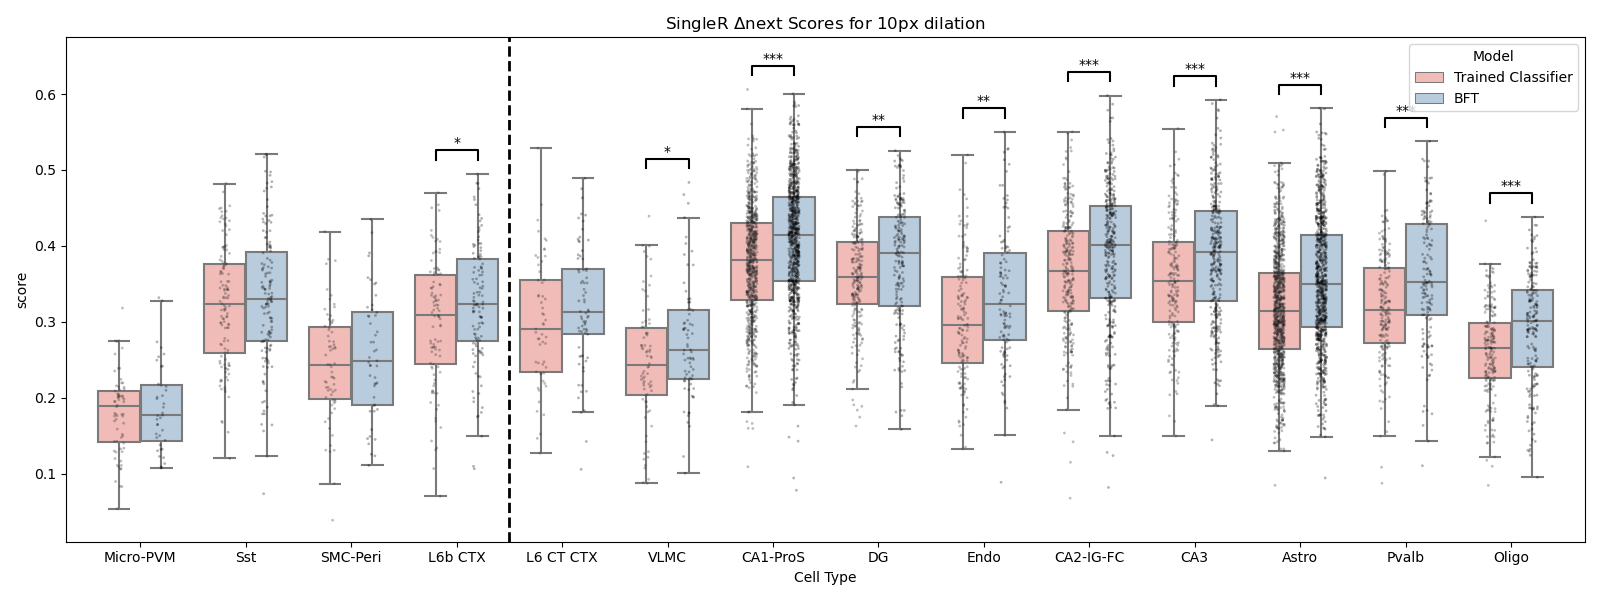

In [23]:
sort_order = list(dict.fromkeys(
    results_df.sort_values(by="gs-bf-median_ratio", ascending=False)['cell_type']
))

plt.close('all')
plt.figure(figsize=(16, 6))
plt.title(f"SingleR $\\Delta$next Scores for {d_px}px dilation")

ax = sns.boxplot(
    x="label_raw",
    y="score",
    hue="data_type",
    data=combined_df_sub,
    palette="Pastel1",
    order=sort_order,
    showfliers=False
)

# Capture handles HERE -- before stripplot appends its own duplicate set.
box_handles, box_labels = ax.get_legend_handles_labels()

sns.stripplot(
    x="label_raw",
    y="score",
    hue="data_type",
    data=combined_df_sub,
    order=sort_order,
    dodge=True,
    color="black",
    alpha=0.3,
    size=2,
)
# No legend= kwarg here: it does not exist before seaborn 0.13, and it is not
# needed. The stripplot does register its own hue handles, but the explicit
# ax.legend(box_handles, ...) at the bottom replaces the legend entirely.

ax.axvline(x=3.5, color="black", linestyle="--", linewidth=2)

# ---------------------------------------------------------------------------
# Significance brackets, one per cell type, driven by results_df
# ---------------------------------------------------------------------------
xpos = {ct: i for i, ct in enumerate(sort_order)}

# Top of the visible data per cell type. Uses raw max because the stripplot
# draws every point, so the boxplot's whisker cap is not the visual ceiling.
tops = combined_df_sub.groupby("label_raw")["score"].max()

ymin, ymax = ax.get_ylim()
span = ymax - ymin
pad = 0.03 * span          # gap between data and bracket
h = 0.02 * span            # bracket height

# With 2 hue levels and default box width 0.8, the dodged boxes sit at +/- 0.2.
n_hue = combined_df_sub["data_type"].nunique()
half = 0.4 - (0.8 / n_hue) / 2

highest = ymax
for _, row in results_df.iterrows():
    ct = row["cell_type"]
    if ct not in xpos:
        continue
    stars = p_to_stars(row["p_value"])
    if not stars:
        continue
    x = xpos[ct]
    y = tops.get(ct, ymin) + pad
    add_significance(ax, x - half, x + half, y, h, stars)
    highest = max(highest, y + h)

# Make room for the brackets and the star glyphs above them.
ax.set_ylim(ymin, highest + 0.06 * span)

ax.set_xlabel("Cell Type")

# ---------------------------------------------------------------------------
# Legend: boxplot entries only
# ---------------------------------------------------------------------------
label_map = {
    f"gs_{d_px}px": "Trained Classifier",
    f"bft_{d_px}px": "BFT",
}
new_labels = [label_map.get(l, l) for l in box_labels]
ax.legend(box_handles, new_labels, title="Model")

plt.tight_layout()

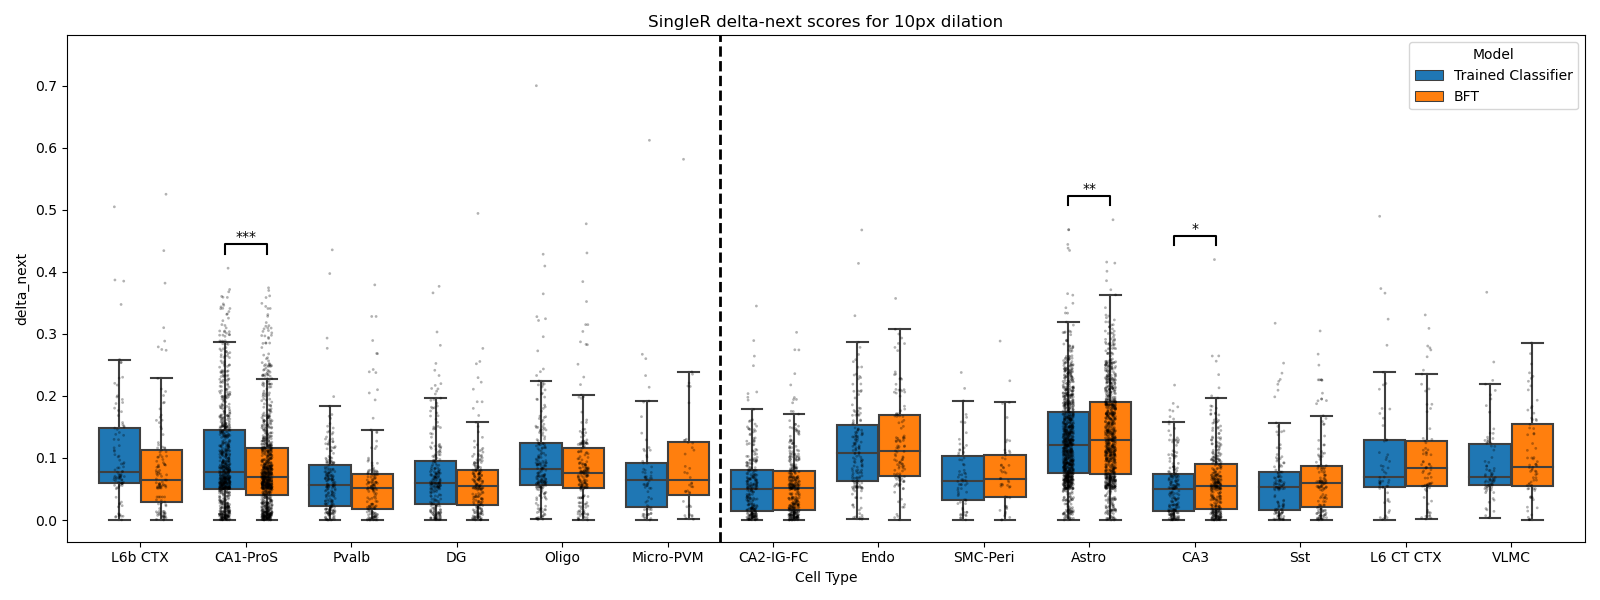

In [ ]:
# ---------------------------------------------------------------------------
# SingleR delta-next box plot, x-axis ordered by GS/BFT median delta-next ratio
# ---------------------------------------------------------------------------
SORT_COL = "gs-bf-median_deltanext"   # median_gs_deltanext / median_bft_deltanext (cell above)
METHOD_COLORS = {'gs': '#1f77b4', 'bft': '#ff7f0e', 'polaris': '#2ca02c', 'starfish': '#9467bd'}
HUE_PALETTE = {f'{m}_{d_px}px': METHOD_COLORS[m] for m in METHOD_ORDER}


def p_to_stars(p):
    """'***' p<0.001, '**' p<0.01, '*' p<0.05, '' otherwise (incl. NaN)."""
    if p is None or np.isnan(p):
        return ''
    for cut, stars in ((0.001, '***'), (0.01, '**'), (0.05, '*')):
        if p < cut:
            return stars
    return ''


def add_significance(ax, x1, x2, y, h, text):
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=1.5, c='black')
    ax.text((x1 + x2) / 2, y + h, text, ha='center', va='bottom')


def plot_singler_box(metric, p_col, sort_col, title, save_name):
    """Box + strip plot of `metric` per cell type; brackets = GS vs each other method.

    Cell types are ordered by `sort_col` (descending). A dashed line is drawn
    just before the first cell type whose `sort_col` value is < 1.
    """
    # --- x-axis order ------------------------------------------------------
    ranked = (results_df.sort_values(sort_col, ascending=False, na_position='last')
                        .drop_duplicates('cell_type')
                        .reset_index(drop=True))
    sort_order = ranked['cell_type'].tolist()

    plt.close('all')
    fig, ax = plt.subplots(figsize=(16, 6))
    ax.set_title(title)

    # --- boxes + points ----------------------------------------------------
    sns.boxplot(x="label_raw", y=metric, hue="data_type", hue_order=HUE_ORDER,
                data=combined_df_sub, palette=HUE_PALETTE, saturation=1,
                order=sort_order, showfliers=False, ax=ax)
    # grab box handles before stripplot adds a duplicate legend set
    box_handles, box_labels = ax.get_legend_handles_labels()
    sns.stripplot(x="label_raw", y=metric, hue="data_type", hue_order=HUE_ORDER,
                  data=combined_df_sub, order=sort_order, dodge=True,
                  palette={dt: "black" for dt in HUE_ORDER}, alpha=0.3, size=2, ax=ax)

    # # --- divider: first cell type with ratio < 1 ---------------------------
    # below_one = np.flatnonzero(ranked[sort_col].to_numpy() < 1)
    # if below_one.size and below_one[0] > 0:          # skip if all on one side
    #     ax.axvline(x=below_one[0] - 0.5, color="black", linestyle="--", linewidth=2)

    # --- significance brackets (GS -> each other method, stacked) ----------
    xpos = {ct: i for i, ct in enumerate(sort_order)}
    tops = combined_df_sub.groupby("label_raw")[metric].max()
    ymin, ymax = ax.get_ylim()
    span = ymax - ymin
    pad, h, step = 0.03 * span, 0.02 * span, 0.07 * span

    width = 0.8 / len(HUE_ORDER)                     # default dodge width split per hue
    offset = {dt: -0.4 + width * (i + 0.5) for i, dt in enumerate(HUE_ORDER)}

    highest = ymax
    for ct, grp in results_long.groupby("cell_type"):
        if ct not in xpos:
            continue
        x, y = xpos[ct], tops.get(ct, ymin) + pad
        for other in HUE_ORDER[1:]:
            hit = grp.loc[grp["other"] == other, p_col]
            stars = p_to_stars(hit.iloc[0]) if len(hit) else ''
            if not stars:
                continue
            add_significance(ax, x + offset[REF], x + offset[other], y, h, stars)
            highest = max(highest, y + h)
            y += step
    ax.set_ylim(ymin, highest + 0.06 * span)

    # --- labels / legend ---------------------------------------------------
    ax.set_xlabel("Cell Type")
    label_map = {f"{m}_{d_px}px": METHOD_LEGEND[m] for m in METHOD_ORDER}
    ax.legend(box_handles, [label_map.get(l, l) for l in box_labels], title="Model")

    fig.tight_layout()
    fig.savefig(os.path.join(_OUT, save_name))
    plt.show()


plot_singler_box(
    metric="delta_next", p_col="p_value_deltanext", sort_col=SORT_COL,
    title=f"SingleR delta-next scores for {d_px}px dilation",
    save_name=f"SingleR_delta_next_score_boxplot_{d_px}px_dilation_{FIG_SUFFIX}.svg",
)